# Proyecto #2 — Pipeline de Machine Learning
## Notebook 02: exploración y selección de la ingeniería de características

**Punto 1 del enunciado** · Responsable: Alfredo Catú (alfredo.mux@galileo.edu) · Rama `alfredo`

**Objetivo:** decidir, con evidencia, qué *lags* y qué transformaciones se usarán para predecir `item_cnt_month`
(unidades vendidas por mes de cada par tienda-producto) en noviembre de 2015 (`date_block_num = 34`).

**Salida de este notebook:** la **lista escrita de variables y transformaciones** (sección 1.c), que el notebook
`03_feature_creation.ipynb` convertirá en un pipeline de sklearn. Aquí no se crean operadores: solo se analiza y se
aplica cada operación una vez para justificarla.

**Regla contra la fuga de información:** todo lo que se calcula para el mes *m* usa solo meses anteriores a *m*,
y todo lo que se "aprende" de los datos (medianas, topes, frecuencias, escaladores) se ajusta **solo con los meses de
entrenamiento (0-26)**.

## 0. Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

from predict_future_sales.dataset import cargar_datos, cargar_ventas_limpias
from predict_future_sales.features import (
    LIMITES_OBJETIVO, LAGS_SELECCIONADOS, MES_FIN_ENTRENAMIENTO, MES_TEST,
    agregar_grupo_categoria, agregar_info_tienda, agregar_lags, antiguedad_item,
    construir_cuadricula_mensual, precio_previo_item,
)
from predict_future_sales.plots import COLOR_NEUTRO, COLOR_PRINCIPAL, COLOR_SECUNDARIO

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
SEMILLA = 42  # reproducibilidad de las operaciones aleatorias (imputación forzada)

2026-11-24 09:24:23.029 | INFO     | predict_future_sales.config:<module>:11 - PROJ_ROOT path is: /Users/alfred/Desktop/predict-future-sales


## 1.a Carga del dataset y selección de lags

### 1.a.1 Carga y cuadrícula mensual tienda × producto

Se cargan los datos **limpios** con `cargar_ventas_limpias()` (decisiones DEC-006 a DEC-011 del EDA: tipos, 6 duplicados,
precio -1 corregido y tiendas 0→57, 1→58, 11→10) y se construye la **cuadrícula mensual** con
`construir_cuadricula_mensual()`:

- Para cada mes 0-33 se combinan **todas las tiendas y todos los productos con registros en ese mes**, y las
  combinaciones sin ventas valen **0** (DEC-008), como recomienda el enunciado.
- Se agregan los 214,200 pares de `test.csv` como **mes 34** con el objetivo vacío (es lo que se va a predecir).

**Por qué esta cuadrícula:** `sales_train` solo registra lo vendido, mientras que `test` es una cuadrícula completa
(42 tiendas × 5,100 productos) donde la mayoría de los valores serán 0 (EDA, 10.b). Si el modelo solo viera filas con
venta, nunca aprendería a predecir ceros. Combinar tiendas y productos **activos en cada mes** (y no los 22,170 productos
en los 34 meses) mantiene la tabla en ~11 millones de filas.

**Limitación a tener en cuenta (sesgo de selección, no fuga):** como cada mes solo incluye productos con al menos una
venta en alguna tienda ese mes, en el entrenamiento un producto "nuevo" **siempre vendió algo en su primer mes**. En `test`
no se sabe si los 363 productos nuevos venderán. Las variables no usan esa información (no hay fuga), pero el modelo podría
**sobreestimar un poco las ventas de productos nuevos**. Se debe revisar en el notebook 04 (por ejemplo, el error en las
filas con `item_sin_historia = 1`).

In [2]:
datos_crudos = cargar_datos()
ventas = cargar_ventas_limpias()
items, categorias, tiendas, test = (
    datos_crudos["items"], datos_crudos["item_categories"], datos_crudos["shops"], datos_crudos["test"]
)

cuadricula = construir_cuadricula_mensual(ventas, test)
historico = cuadricula["date_block_num"] < MES_TEST
print(f"Cuadrícula: {len(cuadricula):,} filas ({historico.sum():,} históricas + {(~historico).sum():,} de test)")
print(f"Memoria: {cuadricula.memory_usage().sum() / 1e6:,.0f} MB")
print(f"Filas históricas con item_cnt_month = 0: {(cuadricula.loc[historico, 'item_cnt_month'] == 0).mean():.2%}")
print("\nitem_cnt_month (meses 0-33):")
display(cuadricula.loc[historico, "item_cnt_month"].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).to_frame().T)

Cuadrícula: 11,128,050 filas (10,913,850 históricas + 214,200 de test)
Memoria: 89 MB
Filas históricas con item_cnt_month = 0: 85.28%

item_cnt_month (meses 0-33):


,count,mean,std,min,50%,90%,99%,99.9%,max
item_cnt_month,"10,913,850.000",0.334,3.417,-22.000,0.000,1.000,5.000,21.000,"2,253.000"


**Interpretación:**
- La cuadrícula tiene **11,128,050 filas**: 10,913,850 de los meses 0-33 y los 214,200 pares de `test` como mes 34.
- El **85.28 % de las filas históricas son 0**: la mayoría de los pares tienda-producto no vende en un mes dado, igual que
  se espera en `test`.
- El objetivo es muy asimétrico: la mediana es 0 y el percentil 99 es 5, pero el máximo llega a **2,253** y el mínimo
  a −22 (devoluciones netas). Esto justifica el recorte a [0, 20] (1.a.2 y 1.b.iv).

### 1.a.2 Partición temporal y objetivo recortado

- **Partición secuencial (no aleatoria)**, como pide el enunciado para *forecasting*: **entrenamiento = meses 0-26** (80 %),
  **validación = meses 27-33** (20 %), **test = mes 34**. En este notebook toda estadística que "aprende" de los datos se
  calcula solo con los meses 0-26.
- **Objetivo recortado `y` = `item_cnt_month` limitado a [0, 20]**, igual que la evaluación de Kaggle. Se justifica en el
  tratamiento de *outliers* (1.b.iv); se aplica desde aquí porque los lags se construyen sobre `y`. El recorte usa
  límites **fijos** (no aprendidos de los datos), por lo que no genera fuga.

In [3]:
cuadricula = cuadricula.merge(items[["item_id", "item_category_id"]], on="item_id", how="left")
cuadricula["item_category_id"] = cuadricula["item_category_id"].astype("int8")
cuadricula["y"] = cuadricula["item_cnt_month"].clip(*LIMITES_OBJETIVO)

periodo = np.select(
    [cuadricula["date_block_num"] <= MES_FIN_ENTRENAMIENTO, cuadricula["date_block_num"] < MES_TEST],
    ["entrenamiento (0-26)", "validación (27-33)"],
    "test (34)",
)
display(pd.Series(periodo).value_counts().rename("filas").to_frame())

,filas
entrenamiento (0-26),9299486
validación (27-33),1614364
test (34),214200


### 1.a.3 Lags candidatos y su relación con las ventas

Un **lag** es el valor de un mes anterior: `par_lag_1` es lo que vendió ese par tienda-producto el mes pasado,
`par_lag_12` hace un año. Se evalúan los lags 1 a 12 del **par** y los lags 1, 2, 3 y 12 de tres niveles **agregados**
(promedio por mes del **producto** en todas las tiendas, de la **tienda** y de la **categoría**).

**Sin fuga:** `agregar_lags()` promedia `y` por mes y nivel y lo **desplaza k meses hacia adelante**: la fila del mes *m*
solo recibe el valor del mes *m − k*. Para el mes 34 los lags salen de los meses 33, 32, 31, … y 22.

La correlación se mide en los meses **12-26** (entrenamiento con los 12 lags definidos). Un lag nulo significa que el par
no estaba en la cuadrícula ese mes, es decir, que no hubo ventas: para medir la relación se toma como 0.

,correlacion_con_y,pct_nulos
par_lag_1,0.592,20.642
par_lag_2,0.464,23.706
par_lag_3,0.397,27.028
par_lag_4,0.351,30.494
par_lag_5,0.322,33.807
par_lag_6,0.297,36.753
par_lag_7,0.275,39.686
par_lag_8,0.259,42.716
par_lag_9,0.244,45.697
par_lag_10,0.230,48.316


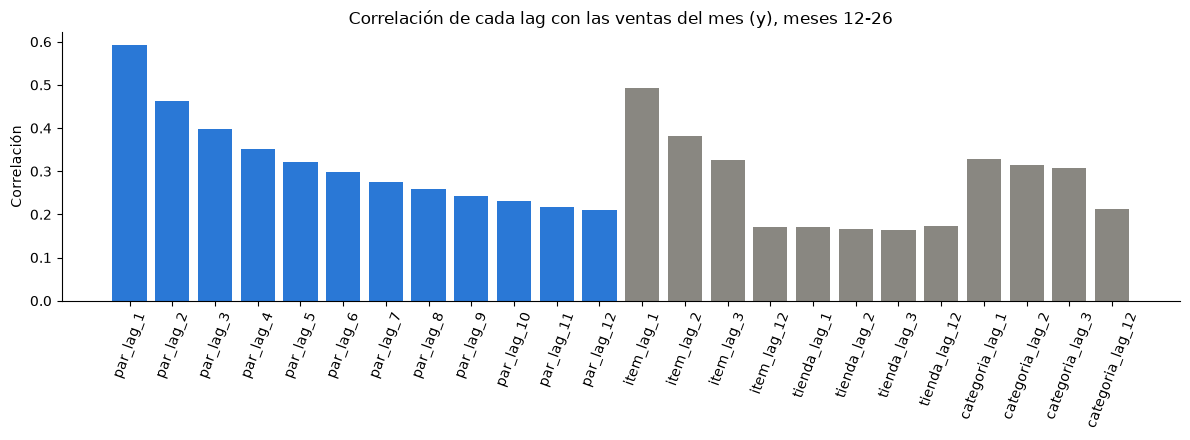

In [4]:
candidatos = {
    "par": (["shop_id", "item_id"], list(range(1, 13))),
    "item": (["item_id"], [1, 2, 3, 12]),
    "tienda": (["shop_id"], [1, 2, 3, 12]),
    "categoria": (["item_category_id"], [1, 2, 3, 12]),
}
exploracion = agregar_lags(cuadricula, "y", candidatos)
columnas_lag = [c for c in exploracion.columns if "_lag_" in c]

ventana = exploracion[exploracion["date_block_num"].between(12, MES_FIN_ENTRENAMIENTO)]
relacion = pd.DataFrame(
    {
        "correlacion_con_y": [np.corrcoef(ventana[c].fillna(0), ventana["y"])[0, 1] for c in columnas_lag],
        "pct_nulos": [ventana[c].isna().mean() * 100 for c in columnas_lag],
    },
    index=columnas_lag,
)
display(relacion.round(3))

fig, ax = plt.subplots(figsize=(12, 4.5))
colores = [COLOR_PRINCIPAL if c.startswith("par_") else COLOR_NEUTRO for c in relacion.index]
ax.bar(relacion.index, relacion["correlacion_con_y"], color=colores)
ax.set_title("Correlación de cada lag con las ventas del mes (y), meses 12-26")
ax.set_ylabel("Correlación")
ax.tick_params(axis="x", rotation=70)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Interpretación:**
- **La relación con las ventas decae de forma gradual con la distancia:** de **0.59** en `par_lag_1` a 0.46 (lag 2),
  0.40 (lag 3) y **0.21** en el lag 12. Es la "persistencia" que el EDA vio como AR(1) (sección 9): lo más reciente es lo
  que más se parece al mes actual.
- **Entre los agregados, el del producto es el más fuerte** (`item_lag_1` = 0.49, casi como el del par): cómo le fue al
  producto en toda la cadena dice mucho de cómo le irá en cada tienda. La categoría aporta 0.33.
- **La tienda tiene correlación baja (0.17), pero casi nunca es nula (< 1 %)**, mientras que los lags del par son nulos en
  el 21-53 % de las filas. Para pares sin historia, el nivel de la tienda y la categoría son la única pista disponible.
- Los lags 12 tienen más nulos (53 % en el par): muchos pares no existían un año antes.

### 1.a.4 ¿Cuántos lags conviene usar? Prueba rápida con RMSE

La correlación mide cada lag por separado; para saber cuánto **aporta** cada grupo de lags junto a los demás se entrena un
modelo simple (regresión lineal) con distintos conjuntos de lags y se mide el **RMSE** (métrica de la competencia; menor
es mejor). **Entrenamiento: meses 12-26** (los que tienen los 12 lags definidos) · **validación: meses 27-33**.
El objetivo no es elegir el modelo (eso es el notebook 04), sino comparar conjuntos de lags en igualdad de condiciones.

In [5]:
def rmse_con_lags(datos, columnas, meses_entrena, meses_valida):
    entrena = datos[datos["date_block_num"].isin(meses_entrena)]
    valida = datos[datos["date_block_num"].isin(meses_valida)]
    modelo = LinearRegression().fit(entrena[columnas].fillna(0), entrena["y"])
    prediccion = modelo.predict(valida[columnas].fillna(0)).clip(*LIMITES_OBJETIVO)
    return float(np.sqrt(np.mean((prediccion - valida["y"]) ** 2)))

seleccion = [f"{nivel}_lag_{k}" for nivel, (_, rezagos) in LAGS_SELECCIONADOS.items() for k in rezagos]
conjuntos = {
    "Solo par 1": ["par_lag_1"],
    "Par 1-3": ["par_lag_1", "par_lag_2", "par_lag_3"],
    "Par 1-3 y 12": ["par_lag_1", "par_lag_2", "par_lag_3", "par_lag_12"],
    "Par 1-12": [f"par_lag_{k}" for k in range(1, 13)],
    "SELECCIÓN (par 1-3, 12 · item 1 · tienda 1, 12 · categoría 1, 12)": seleccion,
    "Todos los candidatos": columnas_lag,
}
meses_entrena, meses_valida = range(12, MES_FIN_ENTRENAMIENTO + 1), range(MES_FIN_ENTRENAMIENTO + 1, MES_TEST)
valida = exploracion[exploracion["date_block_num"].isin(meses_valida)]
comparacion = pd.DataFrame(
    {
        "n_lags": [len(c) for c in conjuntos.values()],
        "RMSE_validacion": [rmse_con_lags(exploracion, c, meses_entrena, meses_valida) for c in conjuntos.values()],
    },
    index=conjuntos.keys(),
)
referencia = {
    "Referencia: predecir siempre 0": float(np.sqrt(np.mean(valida["y"] ** 2))),
    "Referencia: repetir el mes anterior (par_lag_1)": float(
        np.sqrt(np.mean((valida["par_lag_1"].fillna(0) - valida["y"]) ** 2))
    ),
}
display(pd.concat([pd.DataFrame({"n_lags": 0, "RMSE_validacion": referencia.values()}, index=referencia.keys()), comparacion]).round(4))

,n_lags,RMSE_validacion
Referencia: predecir siempre 0,0,1.116
Referencia: repetir el mes anterior (par_lag_1),0,1.037
Solo par 1,1,0.915
Par 1-3,3,0.893
Par 1-3 y 12,4,0.891
Par 1-12,12,0.886
"SELECCIÓN (par 1-3, 12 · item 1 · tienda 1, 12 · categoría 1, 12)",9,0.880
Todos los candidatos,24,0.876


**Interpretación:**
- **Los lags superan claramente a las referencias:** predecir 0 da 1.116 y repetir el mes anterior 1.037; con un modelo
  sobre `par_lag_1` baja a **0.915**.
- **Agregar lags del par rinde cada vez menos:** lags 1-3 → 0.893; sumar el 12 → 0.891; usar los 12 meses → 0.886
  (8 columnas más para ganar 0.005).
- **La SELECCIÓN (9 lags) da 0.880, mejor que los 12 lags del par**: los niveles agregados aportan información distinta a
  la de mirar más atrás en el mismo par.
- **Usar los 24 candidatos solo mejora a 0.876** con 15 columnas más. La selección equilibra precisión y simplicidad.

### 1.a.5 Comprobación para noviembre (mes que se predice)

El test es **noviembre**, y el EDA mostró un pico de fin de año (sección 6) y estacionalidad anual en la serie total
diferenciada (sección 9.5). Se repite la prueba prediciendo **noviembre de 2014 (mes 22)** con entrenamiento en los meses
12-21, para ver si los lags de 12 meses aportan en ese mes en particular.

In [6]:
noviembre = {
    "Par 1-3": ["par_lag_1", "par_lag_2", "par_lag_3"],
    "Par 1-3 y 12": ["par_lag_1", "par_lag_2", "par_lag_3", "par_lag_12"],
    "SELECCIÓN": seleccion,
}
display(
    pd.Series(
        {n: rmse_con_lags(exploracion, c, range(12, 22), [22]) for n, c in noviembre.items()},
        name="RMSE_nov_2014",
    ).round(4).to_frame()
)
del exploracion, ventana, valida

,RMSE_nov_2014
Par 1-3,1.127
Par 1-3 y 12,1.125
SELECCIÓN,1.108


**Interpretación:**
- Noviembre es más difícil de predecir que el promedio (RMSE ~1.11 frente a ~0.88 en los meses 27-33): es el mes
  previo al pico de diciembre.
- `par_lag_12` solo mejora un poco (1.127 → 1.125), pero **la selección, que agrega los lags 12 de tienda y categoría,
  baja a 1.108**. El nivel de la tienda y de la categoría un año antes captura el efecto de fin de año mejor que el par
  (que a menudo no existía un año antes). Por eso se conservan los lags 12 aunque en el promedio aporten poco.

### 1.a.6 Lags seleccionados y verificación contra la fuga de información

Se construyen los lags definitivos (`LAGS_SELECCIONADOS` en `features.py`) y se verifica en un par concreto (tienda 31, producto 10292: DVD "Гадкий я") que el
`par_lag_1` de cada mes es exactamente la venta del mes anterior, y que el mes 34 solo recibe información de meses ≤ 33.

In [7]:
cuadricula = agregar_lags(cuadricula, "y", LAGS_SELECCIONADOS)
columnas_lag = [c for c in cuadricula.columns if "_lag_" in c]

ejemplo = cuadricula[(cuadricula["shop_id"] == 31) & (cuadricula["item_id"] == 10292)].set_index("date_block_num")
comparar = ejemplo[["y", "par_lag_1", "par_lag_12"]].tail(14)
display(comparar.T)
siguiente = ejemplo["par_lag_1"].shift(-1).dropna()
print("¿par_lag_1(m) = y(m-1) en todos los meses?", bool(np.allclose(siguiente, ejemplo.loc[siguiente.index, "y"])))
print("¿El mes 34 tiene objetivo? ", cuadricula.loc[cuadricula["date_block_num"] == MES_TEST, "y"].notna().any())
print("\n% de filas del mes 34 con cada lag disponible:")
display((cuadricula.loc[cuadricula["date_block_num"] == MES_TEST, columnas_lag].notna().mean() * 100).round(1).to_frame("pct_disponible").T)

date_block_num,21,22,23,24,25,26,27,28,29,30,31,32,33,34
y,9.000,4.000,5.000,0.000,4.000,3.000,1.000,3.000,8.000,13.000,10.000,15.000,7.000,NaN
par_lag_1,2.000,9.000,4.000,5.000,0.000,4.000,3.000,1.000,3.000,8.000,13.000,10.000,15.000,7.000
par_lag_12,20.000,17.000,16.000,12.000,9.000,5.000,7.000,3.000,5.000,6.000,2.000,2.000,9.000,4.000


¿par_lag_1(m) = y(m-1) en todos los meses? True
¿El mes 34 tiene objetivo?  False

% de filas del mes 34 con cada lag disponible:


,par_lag_1,par_lag_2,par_lag_3,par_lag_12,item_lag_1,tienda_lag_1,tienda_lag_12,categoria_lag_1,categoria_lag_12
pct_disponible,78.300,69.500,66.200,47.300,78.300,100.000,97.600,100.000,96.700


**Interpretación:**
- **Sin fuga:** en el par de ejemplo, el `par_lag_1` de cada mes es exactamente la venta del mes anterior, y el mes 34 no
  tiene objetivo: sus lags salen de octubre (mes 33) y de noviembre de 2014 (mes 22).
- **Cobertura en el mes 34:** el 78.3 % de los pares tiene `par_lag_1` (el resto no vendió en octubre) y solo el 47.3 %
  tiene `par_lag_12`. Los lags de **tienda y categoría están disponibles en ~97-100 %** de las filas: son los que permiten
  predecir los pares sin historia propia. Los nulos se imputan en 1.b.i.

## 1.b Ingeniería de características: una operación por proceso

Además de los lags, se incorporan variables que el EDA señaló como relevantes, todas **sin fuga**:

| Variable | Origen | Por qué (EDA) |
|---|---|---|
| `precio_previo` | Último precio promedio del producto en un mes **anterior** (`precio_previo_item()`) | El precio define el tipo de producto (sección 5 y 8.c). No se usa el precio del mes porque el de noviembre 2015 no existe en `test` |
| `meses_desde_primera_venta` | Meses desde la primera venta del producto, contando solo meses anteriores (`antiguedad_item()`) | Efecto lanzamiento: las ventas caen ~80 % en seis meses (sección 10.a) |
| `item_category_id`, `grupo_categoria` | `items.csv` y los 14 grupos de DEC-014 | La categoría define volumen y precio típico (sección 7.a y 8.c) |
| `ciudad`, `tipo_tienda` | Mapeo del nombre de la tienda (`agregar_info_tienda()`) | Moscú domina; las tiendas en línea y de evento se comportan distinto (sección 7.b y 8.b) |
| `shop_id`, `item_id` | Identificadores | Variables exógenas que pide el enunciado: identifican la serie |

Cada proceso del enunciado se aplica a continuación con su **criterio de selección**. Los parámetros que se aprenden de los
datos se calculan **solo con los meses 0-26**.

In [8]:
cuadricula = cuadricula.merge(precio_previo_item(ventas), on=["date_block_num", "item_id"], how="left")
cuadricula["meses_desde_primera_venta"] = antiguedad_item(cuadricula, ventas)

info_tiendas = agregar_info_tienda(tiendas)
grupos = agregar_grupo_categoria(categorias)
cuadricula = cuadricula.merge(info_tiendas[["shop_id", "ciudad", "tipo_tienda"]], on="shop_id", how="left")
cuadricula = cuadricula.merge(grupos[["item_category_id", "grupo_categoria"]], on="item_category_id", how="left")
for columna in ["ciudad", "tipo_tienda", "grupo_categoria"]:
    cuadricula[columna] = cuadricula[columna].astype("category")

entrenamiento = cuadricula["date_block_num"] <= MES_FIN_ENTRENAMIENTO
print(f"Filas: {len(cuadricula):,} · columnas: {cuadricula.shape[1]} · memoria: {cuadricula.memory_usage().sum() / 1e6:,.0f} MB")
display(cuadricula[cuadricula["date_block_num"] == 33].head())

Filas: 11,128,050 · columnas: 20 · memoria: 668 MB


,date_block_num,shop_id,item_id,item_cnt_month,item_category_id,y,par_lag_1,par_lag_2,par_lag_3,par_lag_12,item_lag_1,tienda_lag_1,tienda_lag_12,categoria_lag_1,categoria_lag_12,precio_previo,meses_desde_primera_venta,ciudad,tipo_tienda,grupo_categoria
10675678,33,45,13315,1.000,47,1.000,0.000,0.000,NaN,NaN,0.023,0.129,0.135,0.283,NaN,649.000,2.000,Samara,física,Libros
10675679,33,45,13880,1.000,55,1.000,0.000,2.000,4.000,0.000,1.326,0.129,0.135,0.178,0.213,225.037,12.000,Samara,física,Música
10675680,33,45,13881,2.000,55,2.000,1.000,1.000,1.000,2.000,0.791,0.129,0.135,0.178,0.213,647.991,33.000,Samara,física,Música
10675681,33,45,13923,1.000,40,1.000,0.000,0.000,0.000,1.000,0.349,0.129,0.135,0.201,0.230,158.953,33.000,Samara,física,Cine
10675682,33,45,14227,1.000,30,1.000,0.000,0.000,0.000,1.000,2.070,0.129,0.135,0.717,1.207,95.542,23.000,Samara,física,Juegos PC


### 1.b.i Imputación de variables numéricas

En este caso la imputación numérica **no hay que forzarla**: la construcción de variables genera nulos reales.

In [9]:
numericas = columnas_lag + ["precio_previo", "meses_desde_primera_venta"]
nulos = pd.DataFrame(
    {
        "pct_nulos_entrenamiento": cuadricula.loc[entrenamiento, numericas].isna().mean() * 100,
        "pct_nulos_test_mes_34": cuadricula.loc[cuadricula["date_block_num"] == MES_TEST, numericas].isna().mean() * 100,
    }
)
display(nulos.round(2))

,pct_nulos_entrenamiento,pct_nulos_test_mes_34
par_lag_1,22.520,21.750
par_lag_2,28.760,30.460
par_lag_3,34.850,33.850
par_lag_12,75.880,52.660
item_lag_1,21.760,21.750
tienda_lag_1,4.880,0.000
tienda_lag_12,53.480,2.380
categoria_lag_1,4.130,0.020
categoria_lag_12,49.610,3.270
precio_previo,9.850,7.120


**Criterio y operación elegida:**

| Variable | Qué significa el nulo | Imputación | Por qué |
|---|---|---|---|
| Lags (`*_lag_*`) | El par, producto, tienda o categoría **no tuvo registros** ese mes | **Constante 0** | Sin registro = sin ventas (DEC-008). Imputar con la media inventaría ventas que no ocurrieron |
| `precio_previo` | El producto **nunca se vendió antes** (productos nuevos; 7.1 % de los pares de test) | **Mediana del precio de su categoría**, calculada con las ventas de los meses 0-26 | El precio de un producto nuevo se parece al de su categoría (un juego de PS4 no cuesta lo que un DVD). Se usa la mediana porque el precio es muy asimétrico |
| `meses_desde_primera_venta` | El producto **no tiene ventas previas** | **Constante 0** + bandera `item_sin_historia = 1` | 0 = "mes de lanzamiento", coherente con el efecto lanzamiento; la bandera permite al modelo distinguir a los productos nuevos |

In [10]:
mediana_categoria = (
    ventas[ventas["date_block_num"] <= MES_FIN_ENTRENAMIENTO]
    .merge(items[["item_id", "item_category_id"]], on="item_id")
    .groupby("item_category_id")["item_price"].median()
)
mediana_global = float(ventas.loc[ventas["date_block_num"] <= MES_FIN_ENTRENAMIENTO, "item_price"].median())

cuadricula["item_sin_historia"] = cuadricula["meses_desde_primera_venta"].isna().astype("int8")
cuadricula[columnas_lag] = cuadricula[columnas_lag].fillna(0)
cuadricula["meses_desde_primera_venta"] = cuadricula["meses_desde_primera_venta"].fillna(0)
precio_categoria = cuadricula["item_category_id"].map(mediana_categoria).fillna(mediana_global).astype("float32")
cuadricula["precio_previo"] = cuadricula["precio_previo"].fillna(precio_categoria)

print(f"Mediana global de precio (respaldo, meses 0-26): {mediana_global:,.0f}")
print(f"Categorías sin mediana en entrenamiento (usan la global): {cuadricula['item_category_id'].map(mediana_categoria).isna().groupby(cuadricula['item_category_id']).any().sum()}")
print("Nulos restantes en variables numéricas:", int(cuadricula[numericas].isna().sum().sum()))
print(f"Filas con item_sin_historia = 1: entrenamiento {cuadricula.loc[entrenamiento, 'item_sin_historia'].mean():.2%} · test {cuadricula.loc[~historico, 'item_sin_historia'].mean():.2%}")

Mediana global de precio (respaldo, meses 0-26): 399
Categorías sin mediana en entrenamiento (usan la global): 3
Nulos restantes en variables numéricas: 0
Filas con item_sin_historia = 1: entrenamiento 9.85% · test 7.12%


**Interpretación:**
- Los nulos de los lags son altos al inicio del entrenamiento (por ejemplo, `par_lag_12` 75.9 %, porque los primeros
  12 meses no tienen un año previo) y menores en test (52.7 %).
- `precio_previo` y `meses_desde_primera_venta` son nulos en el **9.85 %** del entrenamiento y el **7.12 %** de test: son
  los productos que aún no se habían vendido (en test, los 363 productos nuevos).
- Tras imputar no queda ningún nulo. 3 categorías no tienen ventas en los meses 0-26 y usan la mediana global (399).
- La bandera `item_sin_historia` conserva la información de "producto nuevo" que la imputación habría ocultado.

### 1.b.ii Imputación de variables categóricas (forzada)

Las variables categóricas (`ciudad`, `tipo_tienda`, `grupo_categoria`, `item_category_id`) **no tienen nulos**: vienen de
catálogos completos (DEC-008). Como pide el enunciado, se **fuerza** el proceso borrando al azar el 5 % de `ciudad` y de
`grupo_categoria` en una **copia** (semilla fija para que sea reproducible) y se imputa.

**Criterio:** se imputa con la **categoría constante `"Desconocido"`** y no con la moda. La moda de `ciudad` es Moscú: imputar
con ella asignaría a Moscú tiendas de otras ciudades y sesgaría su nivel de ventas. `"Desconocido"` no inventa información
y el modelo aprende por separado cómo se comportan esos casos.

In [11]:
generador = np.random.default_rng(SEMILLA)
forzado = cuadricula[["ciudad", "grupo_categoria"]].copy()
for columna in forzado.columns:
    borrar = generador.random(len(forzado)) < 0.05
    forzado.loc[borrar, columna] = np.nan
antes = forzado.isna().mean() * 100

moda_entrenamiento = forzado[entrenamiento].mode().iloc[0]
for columna in forzado.columns:
    forzado[columna] = forzado[columna].cat.add_categories("Desconocido").fillna("Desconocido")

display(
    pd.DataFrame(
        {
            "pct_nulos_forzados": antes,
            "pct_nulos_despues": forzado.isna().mean() * 100,
            "moda_entrenamiento (alternativa descartada)": moda_entrenamiento,
            "pct_imputado_como_Desconocido": (forzado == "Desconocido").mean() * 100,
        }
    ).round(2)
)
del forzado

,pct_nulos_forzados,pct_nulos_despues,moda_entrenamiento (alternativa descartada),pct_imputado_como_Desconocido
ciudad,5.000,0.000,Moscú,5.000
grupo_categoria,4.990,0.000,Cine,4.990


**Interpretación:**
- Se borró el 5 % de cada columna y se imputó todo como `"Desconocido"`: no queda ningún nulo.
- La alternativa descartada, la moda, habría asignado ese 5 % a **Moscú** y a **Cine**, que ya son los valores más
  frecuentes (Moscú tiene el 22 % de las filas): exageraría su peso.
- En los datos reales no hay nulos; el imputador se mantendrá en el pipeline (notebook 03) para que funcione si llega una
  tienda o categoría sin mapeo. La copia con nulos forzados se descarta y no afecta a las variables finales.

### 1.b.iii Codificación de variables categóricas

Los modelos solo reciben números. Se elige la codificación según el **número de valores** de cada variable:

| Variable | Valores | Codificación | Por qué |
|---|---|---|---|
| `grupo_categoria` | 14 | **One-hot** (una columna 0/1 por grupo) | Pocos valores y sin orden natural: one-hot no inventa un orden |
| `tipo_tienda` | 3 | **One-hot** | Igual que el anterior |
| `ciudad` | 30 | **Frecuencia** (proporción de filas de entrenamiento de esa ciudad) | One-hot crearía 30 columnas muy dispersas; la frecuencia resume el tamaño del mercado de la ciudad (Moscú concentra muchas tiendas) en una sola columna y se calcula **solo con los meses 0-26** |
| `shop_id`, `item_category_id` | 57 y 84 | Se conservan como **identificador numérico** | Son las variables exógenas que pide el enunciado; los modelos de árboles las separan sin necesidad de one-hot |
| `item_id` | 22,170 | **No entra como variable de entrada**; el producto queda representado por sus lags (`par_lag_*`, `item_lag_1`), su categoría, grupo, precio y antigüedad | One-hot sería inviable, y como número empeora el modelo de árboles (ver *Comprobaciones adicionales*, B). El EDA mostró que la vida del producto es corta: su historia reciente lo describe mejor que el identificador |

In [12]:
frecuencia_ciudad = cuadricula.loc[entrenamiento, "ciudad"].value_counts(normalize=True)
cuadricula["ciudad_frecuencia"] = cuadricula["ciudad"].map(frecuencia_ciudad).astype("float32").fillna(0)

one_hot = pd.get_dummies(cuadricula[["grupo_categoria", "tipo_tienda"]], prefix=["oh_grupo", "oh_tipo"], dtype="int8")
print(f"One-hot: {one_hot.shape[1]} columnas nuevas ->", list(one_hot.columns))
print("\nFrecuencia de ciudad (top 5, meses 0-26):")
display(frecuencia_ciudad.head().round(4).to_frame("frecuencia"))
cuadricula = pd.concat([cuadricula, one_hot], axis=1)
del one_hot

One-hot: 17 columnas nuevas -> ['oh_grupo_Accesorios', 'oh_grupo_Baterías', 'oh_grupo_Cine', 'oh_grupo_Consolas', 'oh_grupo_Juegos PC', 'oh_grupo_Juegos de consola', 'oh_grupo_Juegos digitales móviles/MAC', 'oh_grupo_Libros', 'oh_grupo_Medios vírgenes', 'oh_grupo_Música', 'oh_grupo_Programas', 'oh_grupo_Regalos', 'oh_grupo_Servicios y otros', 'oh_grupo_Tarjetas de pago', 'oh_tipo_en línea', 'oh_tipo_evento', 'oh_tipo_física']

Frecuencia de ciudad (top 5, meses 0-26):


,frecuencia
ciudad,
Moscú,0.222
Tiumén,0.054
Vorónezh,0.046
Samara,0.042
Ufá,0.042


**Interpretación:**
- El one-hot crea **17 columnas** (14 grupos de categoría y 3 tipos de tienda), todas 0/1.
- La frecuencia de ciudad resume el tamaño de cada mercado: **Moscú 0.222**; la siguiente (Tiumén) solo 0.054.
- Como la frecuencia se calcula con los meses 0-26, una ciudad que no aparezca en entrenamiento recibiría 0.

### 1.b.iv Tratamiento de *outliers*

El EDA (secciones 7.c y 8) detectó extremos que se conservaron durante el análisis (DEC-009 y DEC-013 dejaron el recorte
para la etapa de modelado). Ahora se decide:

| Variable | Extremo detectado | Operación | Por qué |
|---|---|---|---|
| `item_cnt_month` (objetivo) | Máximo 2,253; 915 meses negativos (devoluciones netas) | **Recorte a [0, 20]** (ya aplicado en `y`, 1.a.2) | Kaggle evalúa con las predicciones recortadas a [0, 20]: entrenar con 2,253 haría que unos pocos casos (envíos y la bolsa en la tienda en línea) dominen el error. Los límites son fijos: no hay fuga |
| `precio_previo` | Precios hasta ~40,000 frente a una mediana de 399 (en `sales_train` hay un registro aislado de 307,980) | **Tope en el percentil 99.9** de los precios de entrenamiento | Se conserva el orden de los productos caros pero se limita el extremo. El percentil se calcula con los meses 0-26 |

In [13]:
y_original = cuadricula.loc[historico, "item_cnt_month"]
print(f"Objetivo: {(y_original > LIMITES_OBJETIVO[1]).sum():,} meses-par > 20 y {(y_original < 0).sum():,} < 0 "
      f"({((y_original > 20) | (y_original < 0)).mean():.3%} de las filas) quedan recortados.")

tope_precio = float(ventas.loc[ventas["date_block_num"] <= MES_FIN_ENTRENAMIENTO, "item_price"].quantile(0.999))
afectadas = cuadricula["precio_previo"] > tope_precio
print(f"Tope de precio (p99.9 meses 0-26): {tope_precio:,.0f} · filas afectadas: {afectadas.sum():,} ({afectadas.mean():.3%})")
print(f"Precio máximo antes: {cuadricula['precio_previo'].max():,.0f}", end=" -> ")
cuadricula["precio_previo"] = cuadricula["precio_previo"].clip(upper=tope_precio)
print(f"después: {cuadricula['precio_previo'].max():,.0f}")

Objetivo: 11,463 meses-par > 20 y 915 < 0 (0.113% de las filas) quedan recortados.
Tope de precio (p99.9 meses 0-26): 22,990 · filas afectadas: 5,952 (0.053%)
Precio máximo antes: 39,990 -> después: 22,990


**Interpretación:**
- **Objetivo:** se recortan **12,378 meses-par (0.113 %)**: 11,463 por encima de 20 y 915 negativos. Es una fracción
  mínima de filas, pero son las que más distorsionarían el RMSE.
- **Precio:** el tope del percentil 99.9 del entrenamiento es **22,990**; afecta a **5,952 filas (0.053 %)** y baja el
  máximo de 39,990 a 22,990. El precio aislado de 307,980 no llega a la cuadrícula: ese producto solo se vendió ese día.

### 1.b.v Transformación de variables numéricas

El precio y los lags son muy **asimétricos** (muchos valores pequeños y pocos muy grandes). Se evalúa **`log1p`**
(logaritmo de 1 + x), que comprime los valores grandes y admite ceros (`log1p(0) = 0`). No aprende nada de los datos, así
que no tiene riesgo de fuga. Se mide la asimetría (*skew*, ideal cercano a 0) antes y después en el entrenamiento.

**Criterio:** `log1p` se aplica **solo a `precio_previo`**. Los lags se dejan en unidades: aunque `log1p` también reduce su
asimetría, la relación entre las ventas del mes y las del mes anterior es casi **proporcional** (si vendió 10, se espera
del orden de 10), y el logaritmo la deforma. La prueba de *Comprobaciones adicionales* (A) muestra que `log1p` en los lags
empeora el modelo lineal y no cambia el de árboles.

,skew_original,skew_log1p
precio_previo,8.690,0.470
par_lag_1,9.550,3.480
par_lag_2,9.710,3.600
par_lag_3,10.020,3.740
par_lag_12,14.140,5.900
item_lag_1,9.640,3.610
tienda_lag_1,2.060,1.440
tienda_lag_12,2.140,1.550
categoria_lag_1,16.440,2.790
categoria_lag_12,16.780,3.540


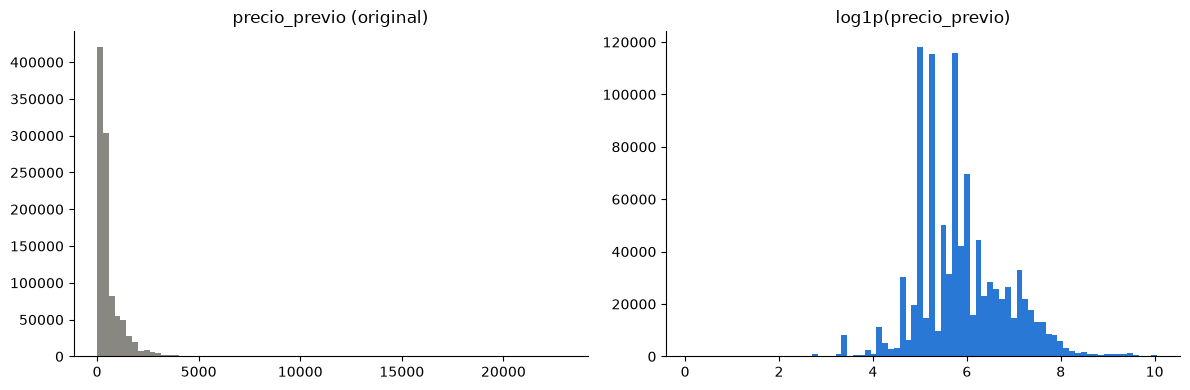

In [14]:
candidatas = ["precio_previo"] + columnas_lag
muestra = cuadricula.loc[entrenamiento, candidatas].sample(1_000_000, random_state=SEMILLA)
asimetria = pd.DataFrame({"skew_original": muestra.skew(), "skew_log1p": np.log1p(muestra).skew()})
display(asimetria.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(muestra["precio_previo"], bins=80, color=COLOR_NEUTRO)
axes[0].set_title("precio_previo (original)")
axes[1].hist(np.log1p(muestra["precio_previo"]), bins=80, color=COLOR_PRINCIPAL)
axes[1].set_title("log1p(precio_previo)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

transformar = ["precio_previo"]  # criterio: log1p solo en el precio (los lags quedan en unidades)
cuadricula[transformar] = np.log1p(cuadricula[transformar]).astype("float32")
del muestra

**Interpretación:**
- **Precio:** la asimetría baja de **8.69 a 0.47**: queda casi simétrico (ver histogramas). Se aplica `log1p`.
- **Lags:** `log1p` bajaría su asimetría de ~9.5-16.8 a ~1.4-5.9 (seguirían asimétricos porque la mayoría de los valores
  son 0), pero **no se aplica** porque deforma su relación proporcional con las ventas (ver *Comprobaciones adicionales*, A).

### 1.b.vi Escalado de características

Las variables quedan en escalas distintas (`meses_desde_primera_venta` de 0 a 34, `ciudad_frecuencia` cercana a 0,
lags de 0 a 20). Se aplica **`StandardScaler`** (media 0, desviación 1), **ajustado solo con los meses 0-26** y
aplicado después a validación y test.

**Criterio:** los modelos lineales y basados en distancias o gradiente (regresión lineal/Ridge, redes, KNN) son sensibles a la
escala; los de árboles (Random Forest, XGBoost, LightGBM) no se ven afectados. Escalar no perjudica a ninguno, así que se
escala para poder comparar en el notebook 04 modelos de ambos tipos con el mismo preprocesamiento.

In [15]:
escalar = transformar + columnas_lag + ["meses_desde_primera_venta", "ciudad_frecuencia"]
escalador = StandardScaler().fit(cuadricula.loc[entrenamiento, escalar])
escaladas = pd.DataFrame(escalador.transform(cuadricula[escalar]), columns=escalar, index=cuadricula.index)

resumen = pd.DataFrame(
    {
        "media_antes": cuadricula.loc[entrenamiento, escalar].mean(),
        "desv_antes": cuadricula.loc[entrenamiento, escalar].std(),
        "media_despues": escaladas.loc[entrenamiento].mean(),
        "desv_despues": escaladas.loc[entrenamiento].std(),
        "media_validacion_despues": escaladas.loc[historico & ~entrenamiento].mean(),
    }
)
display(resumen.round(3))
cuadricula[escalar] = escaladas.astype("float32")
del escaladas

,media_antes,desv_antes,media_despues,desv_despues,media_validacion_despues
precio_previo,5.880,0.967,0.000,1.000,0.242
par_lag_1,0.287,1.221,0.000,1.000,-0.023
par_lag_2,0.274,1.200,0.000,1.000,-0.010
par_lag_3,0.259,1.172,0.000,1.000,0.010
par_lag_12,0.126,0.866,-0.000,1.000,0.124
item_lag_1,0.289,0.866,-0.000,1.000,-0.034
tienda_lag_1,0.291,0.227,0.000,1.000,-0.121
tienda_lag_12,0.148,0.220,-0.000,1.000,0.546
categoria_lag_1,0.294,0.410,0.000,1.000,-0.070
categoria_lag_12,0.172,0.457,-0.000,1.000,0.289


**Interpretación:**
- En el entrenamiento todas las variables quedan con **media 0 y desviación 1**.
- **En validación algunas medias se desplazan**, sobre todo `meses_desde_primera_venta` (1.12), `tienda_lag_12` (0.55) y
  `categoria_lag_12` (0.29). No es un error sino un **cambio en el tiempo**: los productos son más antiguos en los meses
  recientes (los datos empiezan en ene-2013) y los lags 12 valen 0 en los primeros 12 meses. Si afecta al modelo y cómo
  tratarlo se responde en *Comprobaciones adicionales*, C.

### Comprobaciones adicionales (revisión de las decisiones)

Al revisar el proceso surgieron tres preguntas que conviene responder con datos antes de pasar al notebook 03:

- **A.** ¿Conviene aplicar `log1p` también a los lags?
- **B.** ¿Debe `item_id` entrar al modelo como número, o basta con representar al producto por sus lags y su categoría?
- **C.** En 1.b.vi las medias de validación se desplazan (**cambio en el tiempo**). ¿Afecta al modelo y conviene corregirlo?

Se comparan dos tipos de modelo con las variables de este notebook: una **regresión lineal** y un **modelo de árboles**
(`HistGradientBoostingRegressor`), ambos con **todas las filas** de los meses de entrenamiento (con una muestra los
resultados cambiaban de un intento a otro y las diferencias son pequeñas). Salvo que se indique otra
cosa, se entrena con los **meses 0-26** y se valida con los **meses 27-33** (RMSE, menor es mejor). No se busca el mejor
modelo (eso es el notebook 04), sino comparar alternativas en igualdad de condiciones.

In [16]:
from sklearn.ensemble import HistGradientBoostingRegressor

columnas_one_hot = [c for c in cuadricula.columns if c.startswith(("oh_grupo_", "oh_tipo_"))]
variables_base = columnas_lag + ["precio_previo", "meses_desde_primera_venta", "ciudad_frecuencia", "item_sin_historia"] + columnas_one_hot
identificadores = ["shop_id", "item_category_id"]
variables_elegidas = variables_base + identificadores
pd.set_option("display.float_format", "{:,.4f}".format)  # las diferencias de RMSE son pequeñas
ENTRENA, VALIDA = range(0, MES_FIN_ENTRENAMIENTO + 1), range(MES_FIN_ENTRENAMIENTO + 1, MES_TEST)
posicion = {c: i for i, c in enumerate(escalar)}


def en_unidades(columna):
    """Deshace el escalado de una columna (vuelve a sus unidades originales)."""
    return cuadricula[columna] * escalador.scale_[posicion[columna]] + escalador.mean_[posicion[columna]]


def estandarizar(serie):
    """Escala con la media y desviación de los meses 0-26 (sin fuga)."""
    return ((serie - serie[entrenamiento].mean()) / serie[entrenamiento].std()).astype("float32")


def rmse_modelos(X, meses_entrena=ENTRENA, meses_valida=VALIDA):
    """RMSE de validación de un modelo lineal y uno de árboles entrenados con las mismas variables."""
    meses = cuadricula["date_block_num"].to_numpy()
    entrena = np.flatnonzero(np.isin(meses, list(meses_entrena)))
    valida = np.isin(meses, list(meses_valida))
    y = cuadricula["y"].to_numpy()
    lineal = LinearRegression().fit(X.iloc[entrena], y[entrena])
    arboles = HistGradientBoostingRegressor(max_iter=200, random_state=SEMILLA).fit(X.iloc[entrena], y[entrena])
    error = lambda modelo: float(np.sqrt(np.mean((modelo.predict(X[valida]).clip(*LIMITES_OBJETIVO) - y[valida]) ** 2)))
    return {"RMSE_lineal": error(lineal), "RMSE_arboles": error(arboles)}


X = cuadricula[variables_elegidas]
elegido = rmse_modelos(X)
print(f"Variables elegidas: {len(variables_elegidas)} -> RMSE lineal = {elegido['RMSE_lineal']:.4f} · árboles = {elegido['RMSE_arboles']:.4f}")

Variables elegidas: 32 -> RMSE lineal = 0.8730 · árboles = 0.8210


**A. `log1p` en los lags.** Se compara el conjunto elegido (lags en unidades) con el mismo conjunto aplicando `log1p` a
los 9 lags.

In [17]:
X_log = X.assign(**{c: estandarizar(np.log1p(en_unidades(c))) for c in columnas_lag})
tabla_a = pd.DataFrame({"Lags en unidades (elegido)": elegido, "log1p en los lags": rmse_modelos(X_log)}).T
display(tabla_a)
del X_log

,RMSE_lineal,RMSE_arboles
Lags en unidades (elegido),0.8730,0.8210
log1p en los lags,0.9276,0.8210


**Interpretación A:**
- `log1p` en los lags **empeora el modelo lineal de 0.8730 a 0.9276** y **no cambia el de árboles** (0.8210 en ambos):
  los árboles solo usan el orden de los valores, que el logaritmo no altera.
- El lineal necesita la relación casi proporcional entre las ventas del mes y las de meses anteriores; el logaritmo la
  deforma. **Decisión: `log1p` solo en `precio_previo`; los lags quedan en unidades** (1.b.v).

**B. `item_id` como variable de entrada.** Se compara sin identificadores, con `shop_id` e `item_category_id` (elegido)
y agregando además `item_id`.

In [18]:
tabla_b = pd.DataFrame(
    {
        "Sin identificadores": rmse_modelos(cuadricula[variables_base]),
        "+ shop_id, item_category_id (elegido)": elegido,
        "+ shop_id, item_category_id, item_id": rmse_modelos(cuadricula[variables_elegidas + ["item_id"]]),
    }
).T
display(tabla_b)

,RMSE_lineal,RMSE_arboles
Sin identificadores,0.8729,0.8279
"+ shop_id, item_category_id (elegido)",0.8730,0.8210
"+ shop_id, item_category_id, item_id",0.8733,0.8346


**Interpretación B:**
- `shop_id` e `item_category_id` **mejoran el modelo de árboles** (de 0.8279 a 0.8210): permiten separar tiendas y
  categorías con niveles de venta distintos, como pide el enunciado (variables exógenas).
- **Agregar `item_id` lo empeora** (0.8346): con 22,170 valores, el número del producto no tiene un significado que el
  modelo pueda aprovechar y lleva a memorizar productos del entrenamiento. Al lineal no le cambia nada.
- **Decisión: `item_id` no entra como variable de entrada.** El producto queda representado por `par_lag_*`,
  `item_lag_1`, su categoría, grupo, precio, antigüedad y la bandera `item_sin_historia`.

**C. Cambio en el tiempo.** En 1.b.vi, `meses_desde_primera_venta` y los lags 12 tienen medias más altas en validación.
Hay dos causas: (1) los datos empiezan en ene-2013, así que la antigüedad de los productos "viejos" crece con el tiempo
(en el mes 30 puede valer 30, algo imposible en el mes 5); (2) en los meses 0-11 los lags 12 valen 0 porque no hay un
año previo. Se prueban tres posibles correcciones:

1. **Ventana de entrenamiento:** entrenar solo con los meses 12-26 (todos con lag 12 real) en lugar de 0-26.
2. **Tope a la antigüedad:** limitarla a 12 meses para que no siga creciendo, o quitar la variable.
3. **Reentrenar con meses recientes:** para predecir el mes 33, entrenar con los meses 0-26 o con los meses 0-32
   (simula reentrenar con toda la historia antes de predecir el mes 34).

In [19]:
antiguedad = en_unidades("meses_desde_primera_venta")
con_tope = estandarizar(antiguedad.clip(upper=12))
validacion = historico & ~entrenamiento

ventana = pd.DataFrame({"Meses 0-26 (elegido)": elegido, "Meses 12-26": rmse_modelos(X, range(12, MES_FIN_ENTRENAMIENTO + 1))}).T
tope = pd.DataFrame(
    {
        "Antigüedad sin tope (elegido)": {**elegido, "media_validacion_escalada": float(cuadricula.loc[validacion, "meses_desde_primera_venta"].mean())},
        "Antigüedad con tope de 12 meses": {**rmse_modelos(X.assign(meses_desde_primera_venta=con_tope)), "media_validacion_escalada": float(con_tope[validacion].mean())},
        "Sin antigüedad": {**rmse_modelos(X.drop(columns="meses_desde_primera_venta")), "media_validacion_escalada": np.nan},
    }
).T
reentrenar = pd.DataFrame(
    {
        "Entrenar 0-26, predecir mes 33": rmse_modelos(X, ENTRENA, [33]),
        "Entrenar 0-32, predecir mes 33": rmse_modelos(X, range(0, 33), [33]),
    }
).T
for titulo, tabla in [("C.1 Ventana de entrenamiento", ventana), ("C.2 Tope a la antigüedad", tope), ("C.3 Reentrenar con meses recientes", reentrenar)]:
    print(titulo)
    display(tabla)
del X, antiguedad, con_tope

C.1 Ventana de entrenamiento


,RMSE_lineal,RMSE_arboles
Meses 0-26 (elegido),0.8730,0.8210
Meses 12-26,0.8727,0.8225


C.2 Tope a la antigüedad


,RMSE_lineal,RMSE_arboles,media_validacion_escalada
Antigüedad sin tope (elegido),0.8730,0.8210,1.1179
Antigüedad con tope de 12 meses,0.8729,0.8254,0.5280
Sin antigüedad,0.8733,0.8252,NaN


C.3 Reentrenar con meses recientes


,RMSE_lineal,RMSE_arboles
"Entrenar 0-26, predecir mes 33",0.9610,0.9140
"Entrenar 0-32, predecir mes 33",0.9603,0.8895


**Interpretación C:**
- **C.1 Ventana:** entrenar solo con los meses 12-26 no mejora (0.8225 frente a 0.8210 en árboles; el lineal no cambia).
  Los ceros de los lags 12 en los meses 0-11 no perjudican: el modelo aprende que en esos meses no hay información de un
  año antes, y gana más con tener más meses. **Se mantiene la ventana 0-26.**
- **C.2 Antigüedad:** el tope de 12 meses reduce el desplazamiento de la media en validación (de 1.12 a 0.53), pero
  **empeora el modelo** (0.8254), y quitar la variable también (0.8252). La antigüedad completa aporta información.
  **Se mantiene sin tope.**
- **C.3 Reentrenar:** para predecir el mes 33, el modelo de árboles entrenado hasta el mes 32 baja de 0.9140 a **0.8895**
  (−2.7 %): lo que cambia con el tiempo se corrige incorporando los meses más recientes.
- **Conclusión:** el cambio en el tiempo existe pero **no requiere transformar las variables**; se maneja **reentrenando
  el modelo ganador con los meses 0-33 antes de predecir el mes 34** (recomendación para el notebook 04).

## 1.c Proceso de ingeniería de características: lista de variables y transformaciones

Esta es la **receta** que el notebook `03_feature_creation.ipynb` convertirá en un pipeline de sklearn. Las operaciones
marcadas como *aprendidas* se ajustan **solo con los meses de entrenamiento (0-26)** y luego se aplican igual a
validación (27-33) y test (34).

### Paso 1. Preparación previa al pipeline (sobre la cuadrícula ordenada en el tiempo)
1. **Limpieza** del EDA con `cargar_ventas_limpias()` (DEC-006 a DEC-011).
2. **Cuadrícula mensual** tienda × producto con ceros + pares de `test` como mes 34 (`construir_cuadricula_mensual()`).
3. **Objetivo** `y = item_cnt_month` recortado a **[0, 20]** (límites fijos).
4. **Lags** con `agregar_lags()` y `LAGS_SELECCIONADOS`, más `precio_previo_item()` y `antiguedad_item()`: todos usan solo
   meses anteriores. Se construyen antes del pipeline porque necesitan la historia de cada par (no son operaciones fila
   por fila).

### Paso 2. Variables y transformaciones

| Variable | Tipo | Imputación (i, ii) | *Outliers* (iv) | Transformación (v) | Codificación (iii) | Escalado (vi) |
|---|---|---|---|---|---|---|
| `par_lag_1`, `par_lag_2`, `par_lag_3`, `par_lag_12` | Numérica | Constante **0** | Heredan el recorte de `y` | — (en unidades) | — | **StandardScaler** |
| `item_lag_1` | Numérica | Constante **0** | Heredan el recorte de `y` | — (en unidades) | — | **StandardScaler** |
| `tienda_lag_1`, `tienda_lag_12` | Numérica | Constante **0** | Heredan el recorte de `y` | — (en unidades) | — | **StandardScaler** |
| `categoria_lag_1`, `categoria_lag_12` | Numérica | Constante **0** | Heredan el recorte de `y` | — (en unidades) | — | **StandardScaler** |
| `precio_previo` | Numérica | **Mediana del precio de la categoría** (*aprendida*); respaldo: mediana global (399) | **Tope p99.9** (*aprendido*: 22,990) | **log1p** | — | **StandardScaler** |
| `meses_desde_primera_venta` | Numérica | Constante **0** + bandera | — | — | — | **StandardScaler** |
| `item_sin_historia` | Bandera 0/1 | (se crea antes de imputar) | — | — | — | — |
| `ciudad` | Categórica | Constante **"Desconocido"** | — | — | **Frecuencia** (*aprendida*) → `ciudad_frecuencia` | **StandardScaler** |
| `tipo_tienda` | Categórica | Constante **"Desconocido"** | — | — | **One-hot** (3 columnas `oh_tipo_*`) | — |
| `grupo_categoria` | Categórica | Constante **"Desconocido"** | — | — | **One-hot** (14 columnas `oh_grupo_*`) | — |
| `shop_id`, `item_category_id` | Identificadores (exógenas) | — (no tienen nulos) | — | — | Se conservan como número | — |
| `item_id` | Llave del producto | — | — | — | **No entra al modelo** (solo sirve para construir lags y cruces; ver comprobación B) | — |
| **`y`** (objetivo) | Numérica | — | **Recorte [0, 20]** | — | — | — |

**Variables que NO entran al modelo (fuga de información):** `item_cnt_month` del propio mes (es la respuesta),
el precio del propio mes (no existe para noviembre de 2015) y cualquier estadística calculada con los meses de
validación o test. `date_block_num` solo se usa para ordenar y particionar.

### Paso 3. Mecanismos de mapeo
| Mapeo | De → a | Dónde está | Tipo |
|---|---|---|---|
| Tiendas duplicadas | `shop_id` 0→57, 1→58, 11→10 | `MAPEO_TIENDAS_DUPLICADAS` (`dataset.py`, DEC-011) | Fijo |
| Tienda → ciudad | Primera palabra del nombre ruso → ciudad en español (31 claves, 30 valores; `Выездная` → Itinerante, `Интернет-магазин` y `Цифровой` → En línea) | `MAPEO_CIUDAD_ES` (`features.py`) | Fijo |
| Tienda → tipo de tienda | 12 y 55 → en línea · 9 y 20 → evento · resto → física | `TIENDAS_EN_LINEA`, `TIENDAS_EVENTO` (`features.py`) | Fijo |
| Producto → categoría | `item_id` → `item_category_id` | `items.csv` | Fijo |
| Categoría → grupo | Prefijo del nombre ruso → 14 grupos en español | `GRUPOS_CATEGORIA_ES` (`features.py`, DEC-014) | Fijo |
| Ciudad → frecuencia | `ciudad` → proporción de filas de entrenamiento | Se calcula en el pipeline | *Aprendido* (meses 0-26) |
| Categoría → precio típico | `item_category_id` → mediana de `item_price` | Se calcula en el pipeline | *Aprendido* (meses 0-26) |

### Paso 4. Orden de los pasos para el pipeline del notebook 03
1. Mapeos fijos (ciudad, tipo de tienda, grupo de categoría).
2. Bandera `item_sin_historia` (antes de imputar).
3. Imputación numérica (lags y antigüedad → 0; precio → mediana de su categoría).
4. Imputación categórica (`"Desconocido"`).
5. Tope de *outliers* en `precio_previo` (p99.9).
6. `log1p` en `precio_previo`.
7. Codificación: frecuencia de ciudad y one-hot de grupo y tipo de tienda.
8. `StandardScaler` en las variables numéricas continuas.

**Resultado:** 9 lags + 4 variables numéricas (`precio_previo`, `meses_desde_primera_venta`, `ciudad_frecuencia`,
`item_sin_historia`) + 17 columnas one-hot + 2 identificadores (`shop_id`, `item_category_id`) = **32 variables de entrada** para predecir `y`.

### Paso 5. Recomendaciones para los notebooks 03 y 04 (de las *Comprobaciones adicionales*)
- Entrenar con **todos los meses 0-26** (no recortar la ventana a 12-26).
- Mantener `meses_desde_primera_venta` **sin tope**.
- Para predecir el mes 34, **reentrenar el modelo ganador con los meses 0-33** (con los mismos hiperparámetros elegidos en validación).